[[312, 737, 409, 498, 975, 367, 783, 278, ..., 570, 846, 193, 348, 461, 900, 8]]


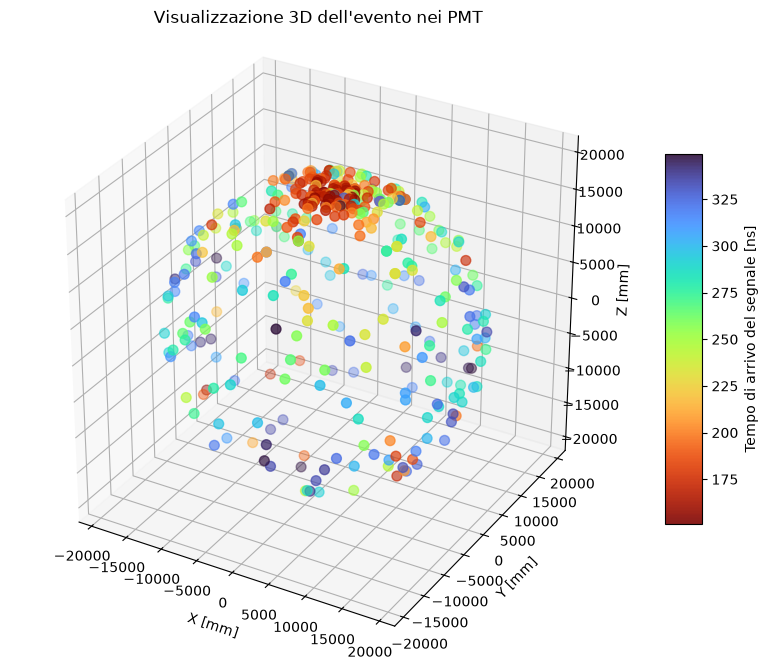

In [1]:
import uproot
import numpy as np 
import matplotlib.pyplot as plt

file = uproot.open("output.root")
tree = file["FilteredTree"]

ids = tree["PMTID"].array()
time = tree["Time"].array()

print( time)

x=[]
y=[]
z=[]

index, x_1, y_1, z_1 = np.loadtxt("pmt_positions.csv", unpack=True, usecols =(0, 1, 2, 3))

x_2=x_1[ids]
y_2=y_1[ids]
z_2=z_1[ids]

mask = (time > 150) & (time < 350)

time_pulito = time[mask]
x= x_2[mask]
y= y_2[mask]
z = z_2[mask]
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

scat = ax.scatter(x, y, z, c=time_pulito, cmap='turbo_r', s=50, alpha=0.9)

ax.set_title("Visualizzazione 3D dell'evento nei PMT")
ax.set_xlabel("X [mm]")
ax.set_ylabel("Y [mm]")
ax.set_zlabel("Z [mm]")

cbar = fig.colorbar(scat, ax=ax, shrink=0.6, aspect=10)
cbar.set_label("Tempo di arrivo del segnale [ns]")

plt.gca().set_aspect('equal')

[107, 111, 113, 101, 104, 98, 89.8, ..., 125, 193, 167, 175, 234, 105, 101]


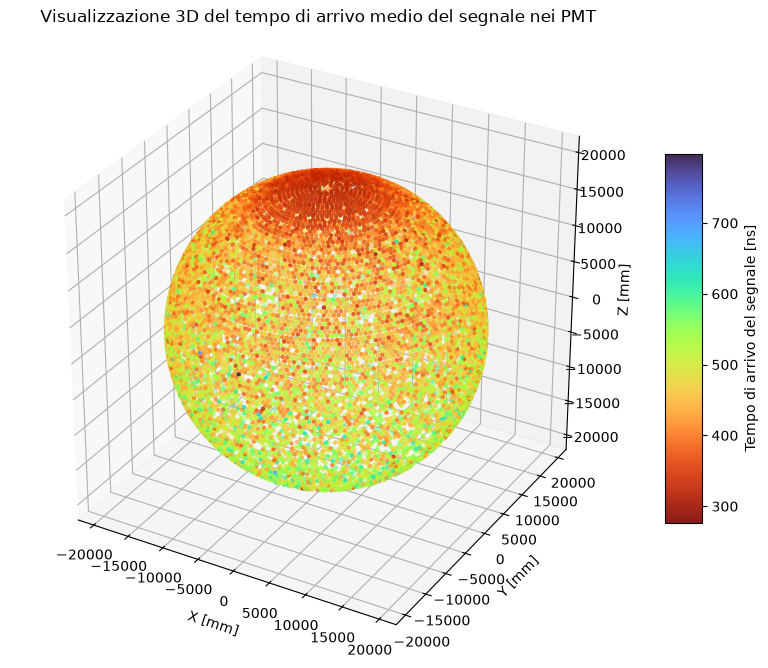

In [9]:
import uproot
import numpy as np 
import matplotlib.pyplot as plt

file = uproot.open("output2.root")
tree = file["PmtStats"]

ids = tree["PMTID"].array()
time = tree["MeanTime"].array()
dev = tree["RMSTime"].array()
print(dev)

x=[]
y=[]
z=[]

index, x_1, y_1, z_1 = np.loadtxt("pmt_positions.csv", unpack=True, usecols =(0, 1, 2, 3))

x_2=x_1[ids]
y_2=y_1[ids]
z_2=z_1[ids]

# mask = (time > 150) & (time < 500)
mask = time>0
time_pulito = time[mask]
x= x_2[mask]
y= y_2[mask]
z = z_2[mask]
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

scat = ax.scatter(x, y, z, c=time_pulito, cmap='turbo_r', s=5, alpha=0.9)

ax.set_title("Visualizzazione 3D del tempo di arrivo medio del segnale nei PMT")
ax.set_xlabel("X [mm]")
ax.set_ylabel("Y [mm]")
ax.set_zlabel("Z [mm]")

cbar = fig.colorbar(scat, ax=ax, shrink=0.6, aspect=10)
cbar.set_label("Tempo di arrivo del segnale [ns]")

plt.gca().set_aspect('equal')

[107, 111, 113, 101, 104, 98, 89.8, ..., 177, 266, 200, 219, 235, 121, 191]


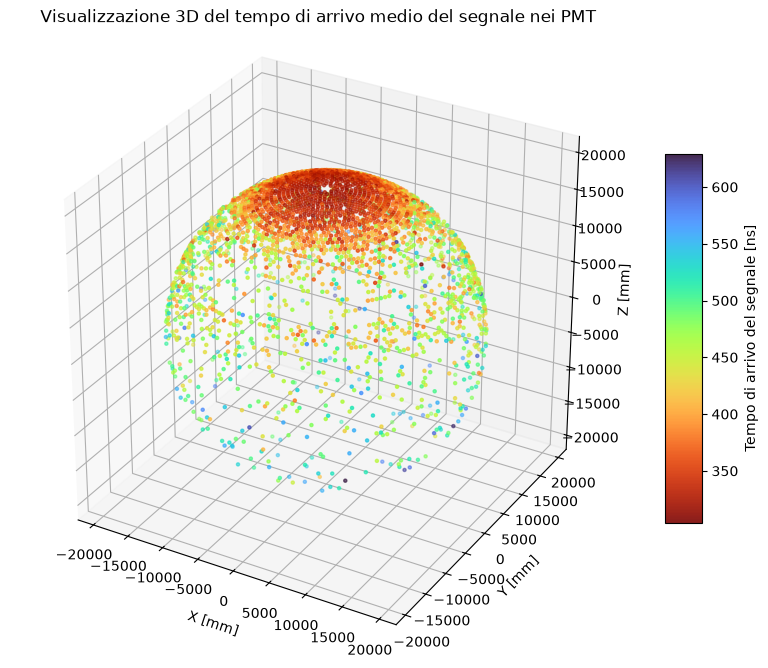

In [13]:
import uproot
import numpy as np 
import matplotlib.pyplot as plt

file = uproot.open("output3.root")
tree = file["PmtStats"]

ids = tree["PMTID"].array()
time = tree["MeanTime"].array()

dev = tree["RMSTime"].array()
print(dev)


x=[]
y=[]
z=[]

index, x_1, y_1, z_1 = np.loadtxt("pmt_positions.csv", unpack=True, usecols =(0, 1, 2, 3))

x_2=x_1[ids]
y_2=y_1[ids]
z_2=z_1[ids]

# mask = (time > 150) & (time < 500)
mask = time >0
time_pulito = time[mask]
x= x_2[mask]
y= y_2[mask]
z = z_2[mask]
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

scat = ax.scatter(x, y, z, c=time_pulito, cmap='turbo_r', s=5, alpha=0.9)

ax.set_title("Visualizzazione 3D del tempo di arrivo medio del segnale nei PMT")
ax.set_xlabel("X [mm]")
ax.set_ylabel("Y [mm]")
ax.set_zlabel("Z [mm]")

cbar = fig.colorbar(scat, ax=ax, shrink=0.6, aspect=10)
cbar.set_label("Tempo di arrivo del segnale [ns]")
plt.gca().set_aspect('equal')

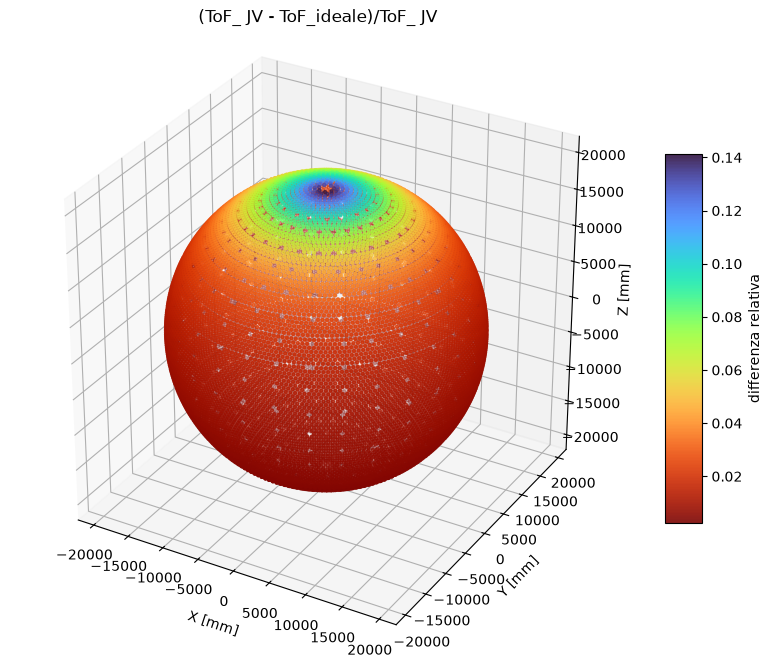

In [6]:
import numpy as np 
import matplotlib.pyplot as plt

time1 = np.loadtxt("arco.dat")
time2 = np.loadtxt("output_ideale.out", usecols=4, unpack=True)

delta_t = time2-time1
delta_t/= time1
x, y, z= np.loadtxt("pmt_positions.csv", unpack=True, usecols =(1, 2, 3))

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

scat = ax.scatter(x, y, z, c=delta_t, cmap='turbo_r', s=5, alpha=0.9)

ax.set_title("(ToF_ JV - ToF_ideale)/ToF_ JV")
ax.set_xlabel("X [mm]")
ax.set_ylabel("Y [mm]")
ax.set_zlabel("Z [mm]")

cbar = fig.colorbar(scat, ax=ax, shrink=0.6, aspect=10)
cbar.set_label("differenza relativa")

plt.gca().set_aspect('equal')

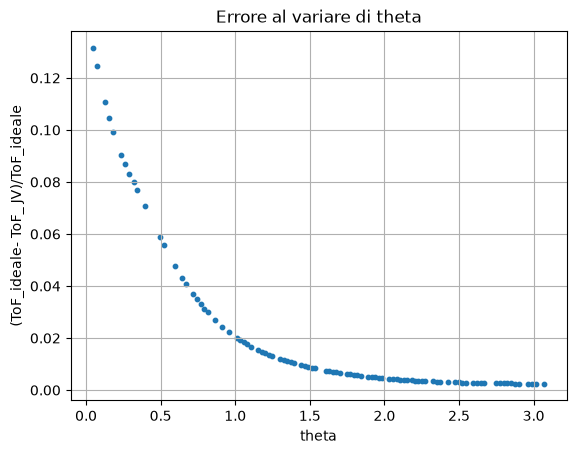

In [12]:
import numpy as np

id= np.loadtxt("pos1.csv", unpack=True, usecols =0, dtype =int)
x, y, z= np.loadtxt("pos1.csv", unpack=True, usecols =(1, 2, 3))
mask= y>0
id=id[mask]
delta_t1= delta_t[id]
x=x[mask]
y=y[mask]
z=z[mask]
theta = np.arccos(z/np.sqrt(x*x +y*y+z*z))

plt.scatter(theta, delta_t1, s=10)
plt.title("Errore al variare di theta")
plt.xlabel("theta")
plt.ylabel("(ToF_ideale- ToF_ JV)/ToF_ideale")
plt.grid()

plt.show()